# Segmenting credit card customers by how they use their card

A card issuer has six months of statements for 30,000 customers: credit limit, monthly bill, monthly payment, and whether each payment was on time. The aim is a small number of segments that a lending or marketing team could act on.

The segments are built from **behaviour only**. Demographics are left out, and so is the label recording whether the customer defaulted the following month. That label is held back and used at the end as an outside check: segments that mean something should differ in risk even though the model never saw it.

Data: *Default of Credit Card Clients*, Taiwan, April to September 2005 (UCI Machine Learning Repository, CC BY 4.0). Amounts are in New Taiwan dollars.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from segments.cluster import (bootstrap_stability, compare_k, fit_kmeans, match_labels,
                              ward_labels)
from segments.features import FEATURES, build_features, load
from segments.profile import profile

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")

df = load("data/credit_card_clients.csv")
df.shape

(30000, 25)

## 1. From statements to behaviour

Each month has a repayment status: **-2** no spending, **-1** paid in full, **0** revolving (paid at least the minimum and carried the rest), **1 to 8** months behind. Raw bill amounts are mostly a function of the credit limit, so the features are ratios and shares that compare customers on equal terms:

| Feature | Meaning |
|---|---|
| `log_limit` | credit limit, log scale |
| `utilisation` | average bill as a share of the limit |
| `share_inactive`, `share_paid_full`, `share_revolving`, `share_late` | share of the six months spent in each repayment status |
| `payment_ratio` | total paid over total billed |

In [2]:
features = build_features(df)
features.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_limit,30000.0,5.07,0.41,4.0,4.70,5.15,5.38,6.0
utilisation,30000.0,0.37,0.35,0.0,0.03,0.29,0.69,1.2
share_inactive,30000.0,0.14,0.30,0.0,0.00,0.00,0.00,1.0
share_paid_full,30000.0,0.19,0.32,0.0,0.00,0.00,0.33,1.0
share_revolving,30000.0,0.53,0.42,0.0,0.00,0.67,1.00,1.0
share_late,30000.0,0.14,0.26,0.0,0.00,0.00,0.17,1.0
payment_ratio,30000.0,0.39,0.42,0.0,0.05,0.12,0.94,1.5


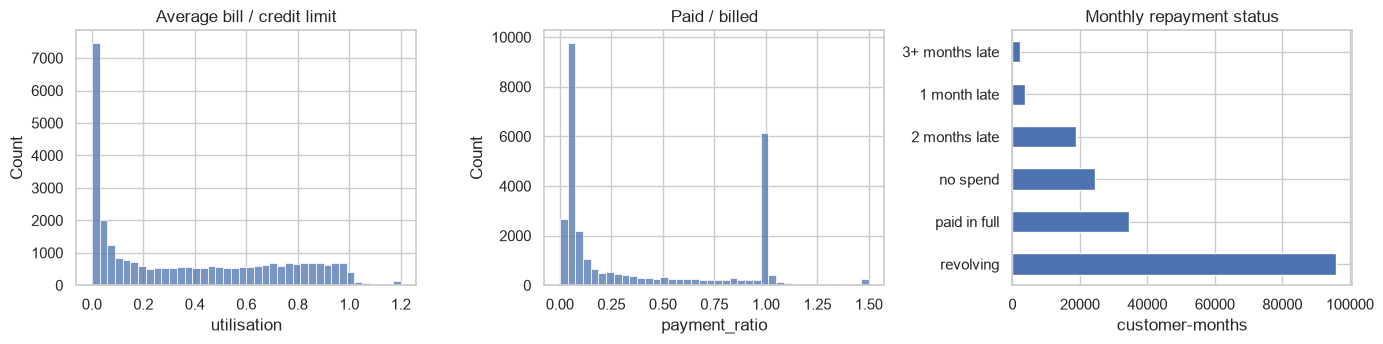

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
sns.histplot(features["utilisation"], bins=40, ax=axes[0])
sns.histplot(features["payment_ratio"], bins=40, ax=axes[1])
status = df[["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]].stack().clip(upper=3)
status.map({-2: "no spend", -1: "paid in full", 0: "revolving", 1: "1 month late",
            2: "2 months late", 3: "3+ months late"}).value_counts().plot.barh(ax=axes[2])
axes[0].set_title("Average bill / credit limit")
axes[1].set_title("Paid / billed")
axes[2].set_title("Monthly repayment status")
axes[2].set_xlabel("customer-months")
plt.tight_layout()

The payment ratio is split in two: a large group pays back about a tenth of what it is billed, and another pays everything. That split will drive most of what follows.

## 2. How many segments?

Features are standardised so that no single one dominates the distances. Three common measures are compared for 2 to 9 clusters with k-means. Higher silhouette is better; lower Davies-Bouldin is better.

In [4]:
X = StandardScaler().fit_transform(features)
scores = compare_k(X, range(2, 10))
scores.round(3)

,inertia,silhouette,davies_bouldin
k,,,
2,124144.295,0.416,1.096
3,93883.719,0.410,0.969
4,65506.841,0.457,0.854
5,52731.064,0.382,0.950
6,47143.382,0.358,0.963
7,43441.655,0.335,1.115
8,40260.874,0.329,1.160
9,37400.482,0.332,1.125


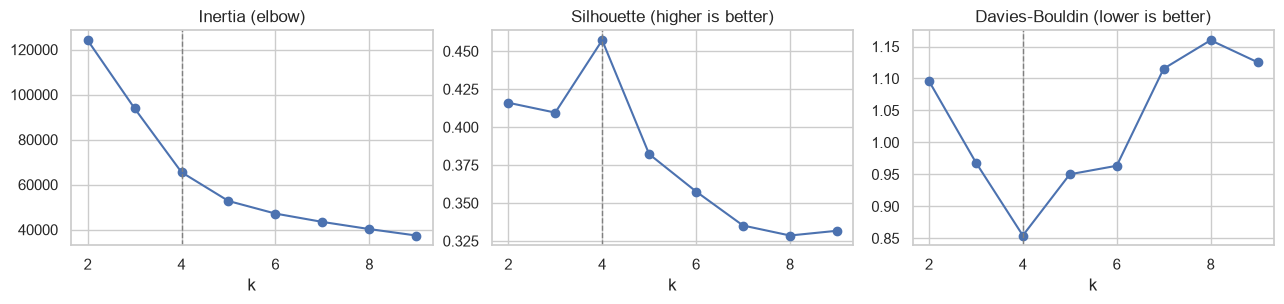

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col, title in zip(axes, scores.columns, ["Inertia (elbow)", "Silhouette (higher is better)",
                                                  "Davies-Bouldin (lower is better)"]):
    ax.plot(scores.index, scores[col], marker="o")
    ax.axvline(4, color="grey", ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlabel("k")
plt.tight_layout()

Both quality measures pick **four** segments, and the elbow bends there too.

A choice of k is only useful if the same segments come back when the data changes a little. Each k is refitted on 20 bootstrap resamples of the customers, and each refit is compared with the original using the adjusted Rand index (1 means identical segment assignments).

In [6]:
stability = pd.DataFrame({k: bootstrap_stability(X, k, n_boot=20) for k in range(2, 9)})
stability.agg(["mean", "min"]).T.round(3)

,mean,min
2,0.998,0.996
3,0.996,0.985
4,0.996,0.983
5,0.989,0.959
6,0.970,0.658
7,0.915,0.741
8,0.933,0.833


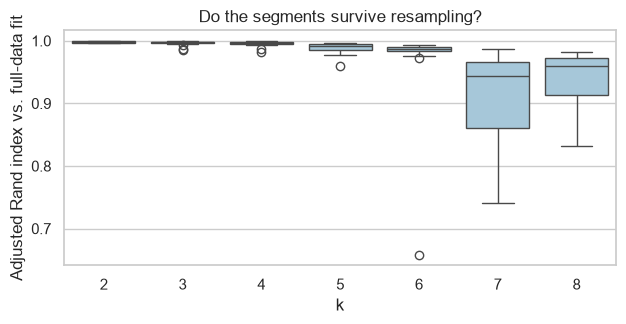

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
sns.boxplot(data=stability, ax=ax, color="#9ecae1")
ax.set_xlabel("k")
ax.set_ylabel("Adjusted Rand index vs. full-data fit")
ax.set_title("Do the segments survive resampling?")
plt.tight_layout()
plt.savefig("images/stability.png", dpi=150)

Up to five segments are stable (the worst resample still agrees above 0.95). From six onwards some resamples split the customers quite differently, so the extra segments are artefacts of a particular sample rather than real groups.

## 3. Does a different algorithm find the same segments?

K-means assumes round clusters of similar size. Ward hierarchical clustering makes different assumptions, so agreement between the two is a further check. Ward needs the full pairwise distance matrix, so it is run on a random sample of 8,000 customers.

In [8]:
kmeans = fit_kmeans(X, 4)
labels = kmeans.labels_

rng = np.random.default_rng(0)
sample = rng.choice(len(X), 8000, replace=False)
ward = match_labels(labels[sample], ward_labels(X[sample], 4))
print(f"Adjusted Rand index: {adjusted_rand_score(labels[sample], ward):.2f}")
print(f"Customers placed in the same segment: {(ward == labels[sample]).mean():.0%}")
pd.crosstab(pd.Series(labels[sample], name="k-means"), pd.Series(ward, name="Ward"))

Adjusted Rand index: 0.78
Customers placed in the same segment: 91%


Ward,0,1,2,3
k-means,,,,
0,4105,0,7,12
1,49,1023,0,0
2,225,108,1422,0
3,283,0,0,766


The two methods put 91% of customers in the same segment. The segments are a property of the data, not of k-means.

## 4. Who is in each segment

In [9]:
table = profile(features, labels, df["default"])
order = table.sort_values("default_rate").index
table = table.loc[order]
names = table["segment"].to_dict()
segment = pd.Series(labels).map(names).rename("segment")
table.round(2)

,segment,customers,share,log_limit,utilisation,share_inactive,share_paid_full,share_revolving,share_late,payment_ratio,default_rate
0,Revolving balance,15323,0.51,5.02,0.54,0.02,0.03,0.91,0.05,0.11,0.16
2,Pays in full,6698,0.22,5.23,0.05,0.06,0.74,0.14,0.06,0.88,0.16
1,Dormant,3956,0.13,5.27,0.03,0.85,0.06,0.03,0.05,0.97,0.19
3,Behind on payments,4023,0.13,4.75,0.62,0.01,0.02,0.25,0.71,0.08,0.59


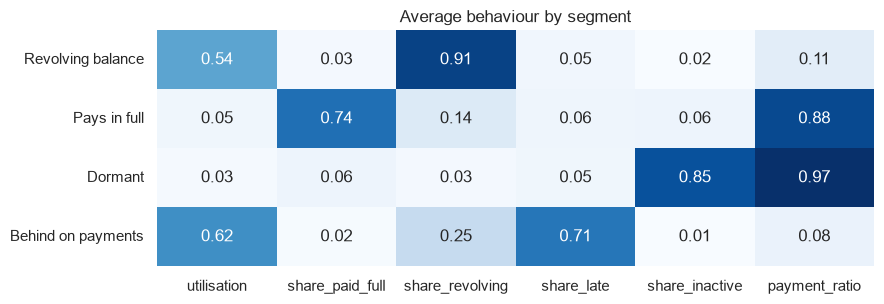

In [10]:
view = table.set_index("segment")[["utilisation", "share_paid_full", "share_revolving",
                                    "share_late", "share_inactive", "payment_ratio"]]
fig, ax = plt.subplots(figsize=(9, 3.2))
sns.heatmap(view, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax)
ax.set_ylabel("")
ax.set_title("Average behaviour by segment")
plt.tight_layout()
plt.savefig("images/profiles.png", dpi=150)

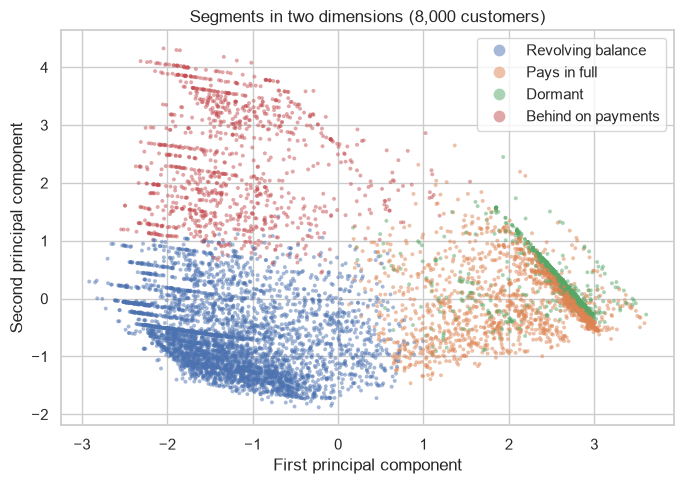

In [11]:
coords = PCA(n_components=2, random_state=0).fit_transform(X)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=coords[sample, 0], y=coords[sample, 1], hue=segment.iloc[sample].to_numpy(),
                hue_order=list(names.values()), s=8, alpha=0.5, linewidth=0, ax=ax)
ax.set_xlabel("First principal component")
ax.set_ylabel("Second principal component")
ax.set_title("Segments in two dimensions (8,000 customers)")
ax.legend(title="", markerscale=3)
plt.tight_layout()

The four segments, in order of risk:

- **Pays in full** (about a fifth of customers): uses under a tenth of the limit and clears the bill most months. These are transactors. The issuer earns interchange fees from them but little interest.
- **Revolving balance** (half): carries a balance of about half the limit and repays roughly a tenth of the bill each month, but on time. This is the issuer's interest income.
- **Dormant** (an eighth): no spending in most months, with high limits that are almost unused.
- **Behind on payments** (an eighth): the smallest limits, and late in more than half of the six months.

## 5. An outside check: default next month

The default label was not used to build the segments.

In [12]:
defaults = df.groupby(segment)["default"].agg(["mean", "sum"])
defaults["share_of_all_defaults"] = defaults["sum"] / defaults["sum"].sum()
defaults = defaults.loc[list(names.values())]
defaults.round(2)

,mean,sum,share_of_all_defaults
segment,,,
Revolving balance,0.16,2415,0.36
Pays in full,0.16,1098,0.17
Dormant,0.19,753,0.11
Behind on payments,0.59,2370,0.36


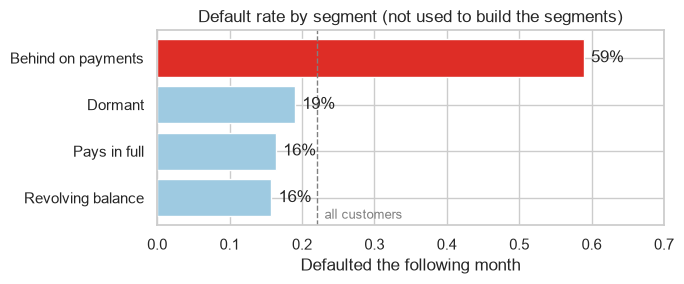

In [13]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(defaults.index, defaults["mean"], color=["#9ecae1"] * 3 + ["#de2d26"])
ax.axvline(df["default"].mean(), color="grey", ls="--", lw=1)
ax.text(df["default"].mean() + 0.01, -0.45, "all customers", color="grey", fontsize=9)
for i, v in enumerate(defaults["mean"]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center")
ax.set_xlim(0, 0.7)
ax.set_xlabel("Defaulted the following month")
ax.set_title("Default rate by segment (not used to build the segments)")
plt.tight_layout()
plt.savefig("images/default_by_segment.png", dpi=150)

**Behind on payments** defaults at nearly four times the rate of the other segments, and is a third of all defaults from an eighth of the customers. The other three segments differ little in risk. They differ in how they make money for the issuer, which is what they are for.

One surprise: **dormant** customers default slightly more often than revolvers, despite owing almost nothing. A customer who has stopped using a card may have moved their spending to another lender.

### Segments are not a credit score

How well would the segments rank customers by risk, compared with a model trained on the same features to predict default? Both are scored out of fold with five-fold cross-validation.

In [14]:
y = df["default"].to_numpy()
folds = StratifiedKFold(5, shuffle=True, random_state=0)

segment_score = np.zeros(len(y))
for train, test in folds.split(X, y):
    model = fit_kmeans(X[train], 4)
    rate = pd.Series(y[train]).groupby(model.labels_).mean()
    segment_score[test] = rate.reindex(model.predict(X[test])).to_numpy()

logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model_score = cross_val_predict(logistic, features, y, cv=folds, method="predict_proba")[:, 1]

pd.Series({
    "Four segments (default rate of the segment)": roc_auc_score(y, segment_score),
    "Share of months late, on its own": roc_auc_score(y, features["share_late"]),
    "Logistic regression on all seven features": roc_auc_score(y, model_score),
}, name="ROC AUC").round(3).to_frame()

,ROC AUC
Four segments (default rate of the segment),0.651
"Share of months late, on its own",0.726
Logistic regression on all seven features,0.752


The segments rank risk well below a simple model (AUC 0.65 against 0.75), and even one feature, the share of months late, beats them. That is expected: a segment gives everyone inside it the same score. Segments are for deciding **what to do** with a group of customers. Deciding **how risky** a particular customer is needs a scoring model.

### Demographics

Age, sex and education were left out of the clustering. They differ only a little between segments, so behaviour carries information that demographics do not.

In [15]:
demographics = df.assign(segment=segment, female=df["SEX"].eq(2),
                         university=df["EDUCATION"].isin([1, 2]))
demographics.groupby("segment")[["AGE", "female", "university"]].mean().loc[list(names.values())].round(2)

,AGE,female,university
segment,,,
Revolving balance,34.98,0.59,0.81
Pays in full,36.28,0.64,0.85
Dormant,36.68,0.66,0.86
Behind on payments,34.93,0.54,0.79


## 6. What to do with each segment

| Segment | Share | Default rate | Suggested action |
|---|---|---|---|
| Pays in full | ~22% | 16% | Rewards and spending offers; no interest income to protect |
| Revolving balance | ~51% | 16% | Core interest income; balance-transfer and instalment offers |
| Dormant | ~13% | 19% | Re-activation offers; review unused high limits, which carry capital cost |
| Behind on payments | ~13% | 59% | Early collections contact, payment plans; no limit increases |

## Limits

- The data comes from one Taiwanese issuer in 2005, during a period of rising card debt there. The default rate (22%) is far higher than in most portfolios today.
- Six months is a short history; a dormant customer may simply be between purchases.
- The default label is one month ahead, so it measures short-term distress rather than lifetime losses.